In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/kaggle/input/datasets/sobhanmoosavi/us-accidents/US_Accidents_March23.csv')
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,...,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,...,False,False,False,False,True,False,Day,Day,Day,Day


In [ ]:
df.columns

In [ ]:
df.shape

In [4]:
df_sample = df.sample(n=100000, random_state=42).copy()
df_sample.shape

(100000, 46)

In [ ]:
df_sample.isnull().sum()

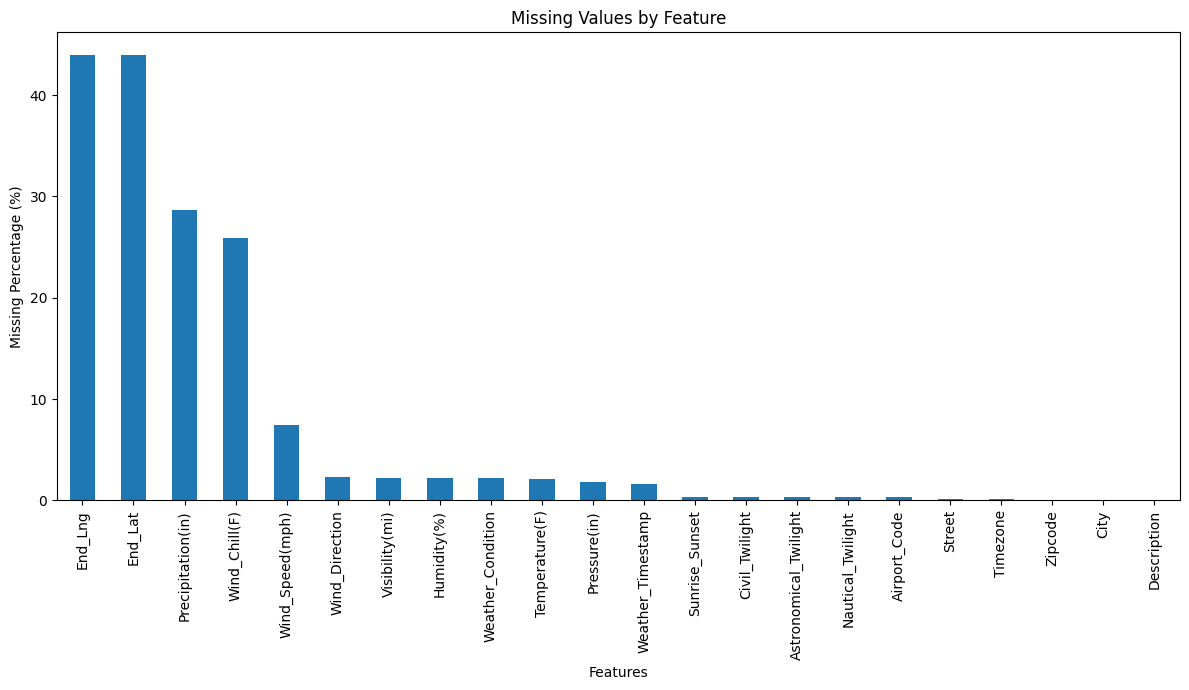

In [5]:
import matplotlib.pyplot as plt

missing_percent = (
    df_sample.isnull().mean() * 100
).sort_values(ascending=False)

missing_percent = missing_percent[
    missing_percent > 0
]

plt.figure(figsize=(12, 7))

missing_percent.plot(kind="bar")

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [6]:
print(df_sample.isnull().sum().sum())
print("Total cells:", df_sample.size)
print(
    "Overall missing percentage:",
    df_sample.isnull().sum().sum() / df_sample.size * 100
)

166436
Total cells: 4600000
Overall missing percentage: 3.6181739130434787


In [7]:
numeric_cols = df_sample.select_dtypes(include=["int64", "float64"]).columns
print(numeric_cols.tolist())

['Severity', 'Start_Lat', 'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']


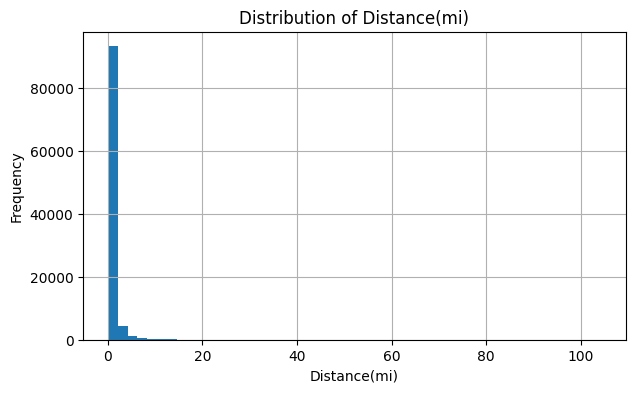

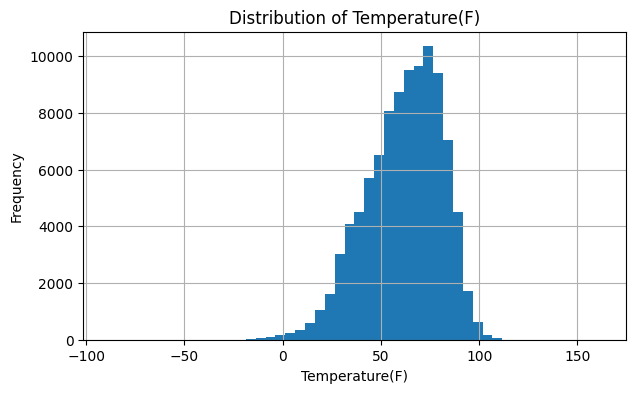

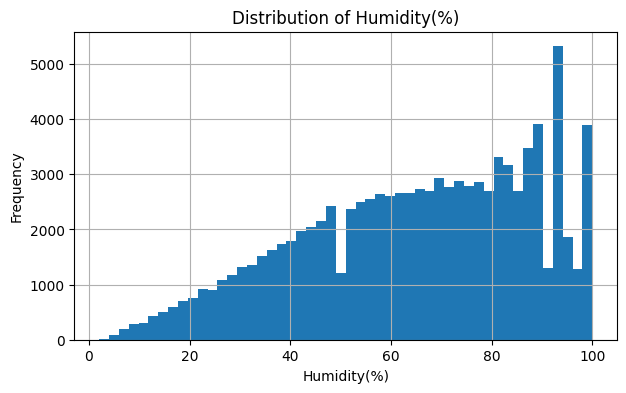

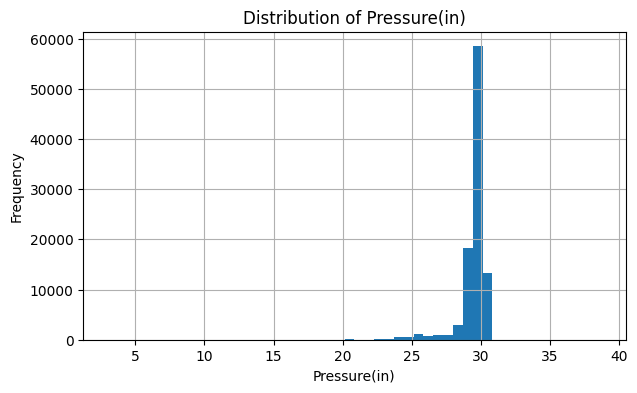

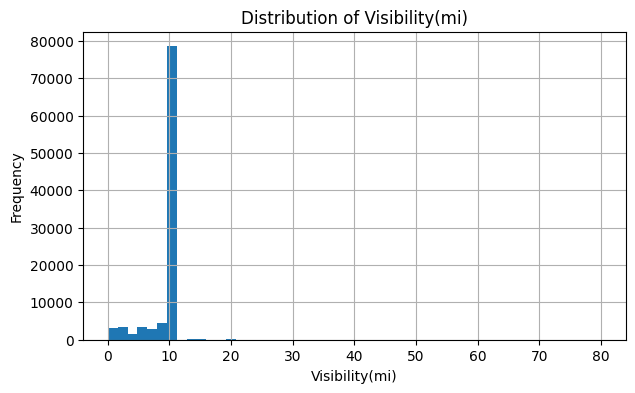

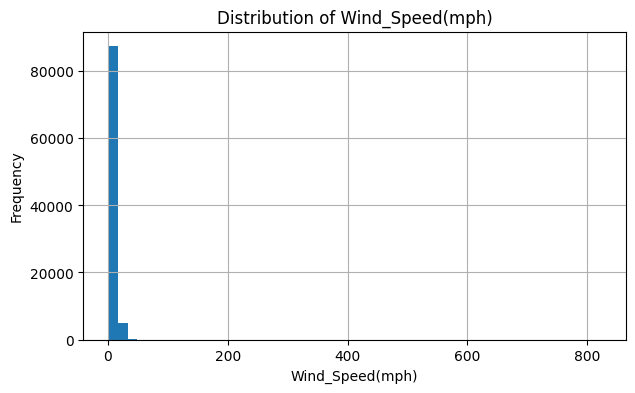

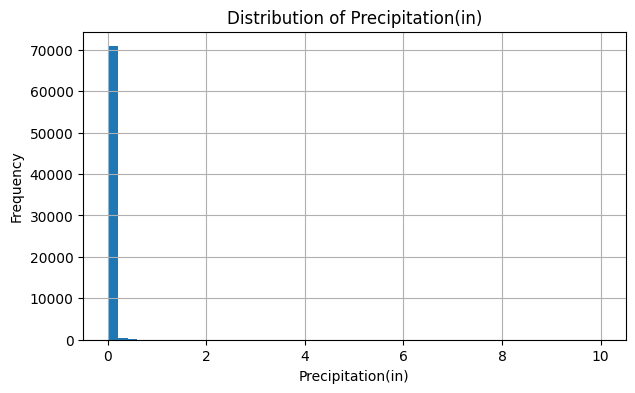

In [8]:
import matplotlib.pyplot as plt
features = [
    "Distance(mi)",
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)"
]
for col in features:
    plt.figure(figsize=(7, 4))
    df_sample[col].dropna().hist(bins=50)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

In [9]:
for col in features:
    Q1 = df_sample[col].quantile(0.25)
    Q3 = df_sample[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df_sample[
        (df_sample[col] < lower) |
        (df_sample[col] > upper)
    ]
    print(f"\n{col}")
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("Potential outliers:", len(outliers))


Distance(mi)
Lower bound: -0.6885
Upper bound: 1.1475
Potential outliers: 12580

Temperature(F)
Lower bound: 8.5
Upper bound: 116.5
Potential outliers: 703

Humidity(%)
Lower bound: -6.0
Upper bound: 138.0
Potential outliers: 0

Pressure(in)
Lower bound: 28.354999999999997
Upper bound: 31.035000000000004
Potential outliers: 5783

Visibility(mi)
Lower bound: 10.0
Upper bound: 10.0
Potential outliers: 19237

Wind_Speed(mph)
Lower bound: -4.100000000000001
Upper bound: 19.1
Potential outliers: 2698

Precipitation(in)
Lower bound: 0.0
Upper bound: 0.0
Potential outliers: 6976


In [10]:
features_to_check = [
    "Distance(mi)",
    "Temperature(F)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)"
]
for col in features_to_check:
    print("\n", col)
    print(df_sample[col].describe(
        percentiles=[0.01, 0.05, 0.95, 0.99]
    ))
    print("Lowest values:")
    print(df_sample[col].nsmallest(5).tolist())
    print("Highest values:")
    print(df_sample[col].nlargest(5).tolist())


 Distance(mi)
count    100000.000000
mean          0.558467
std           1.723387
min           0.000000
1%            0.000000
5%            0.000000
50%           0.029000
95%           2.662050
99%           6.972010
max         104.302000
Name: Distance(mi), dtype: float64
Lowest values:
[0.0, 0.0, 0.0, 0.0, 0.0]
Highest values:
[104.302, 89.31299999999997, 74.4000015258789, 74.172, 69.69000244140625]

 Temperature(F)
count    97880.000000
mean        61.505903
std         19.099270
min        -89.000000
1%          12.000000
5%          28.000000
50%         64.000000
95%         89.000000
99%         96.000000
max        162.000000
Name: Temperature(F), dtype: float64
Lowest values:
[-89.0, -35.0, -26.0, -25.0, -24.0]
Highest values:
[162.0, 122.0, 115.0, 115.0, 114.0]

 Pressure(in)
count    98183.000000
mean        29.533985
std          1.012882
min          3.010000
1%          24.570000
5%          27.860000
50%         29.850000
95%         30.260000
99%         30.440000

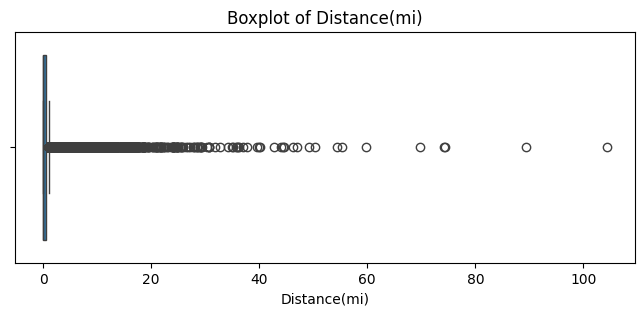

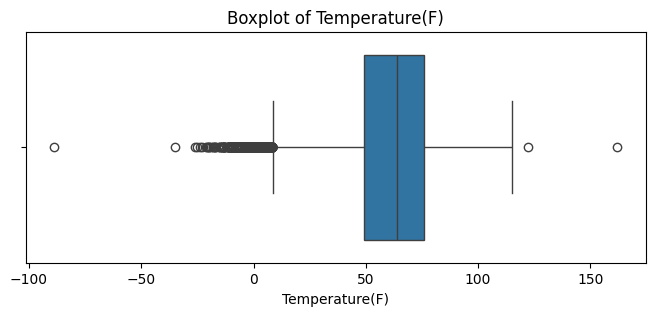

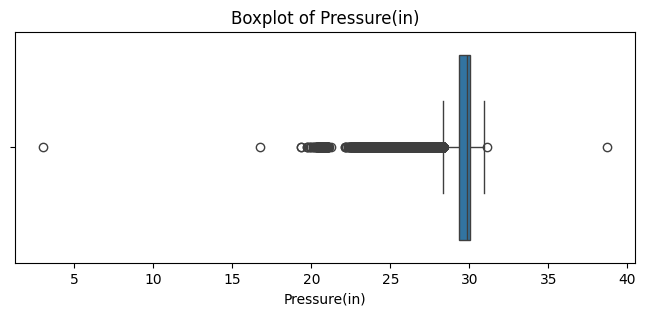

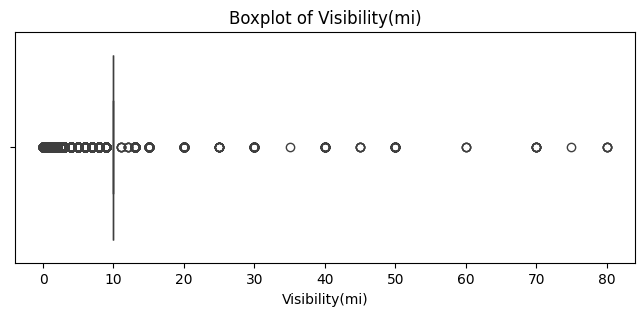

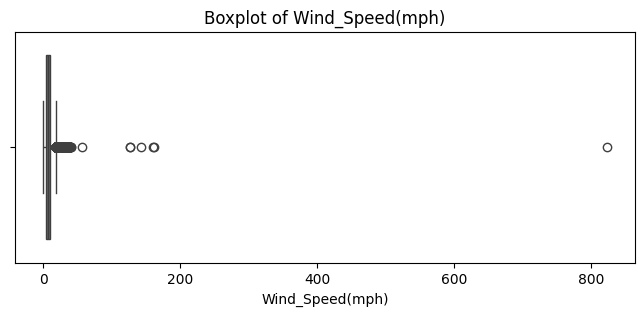

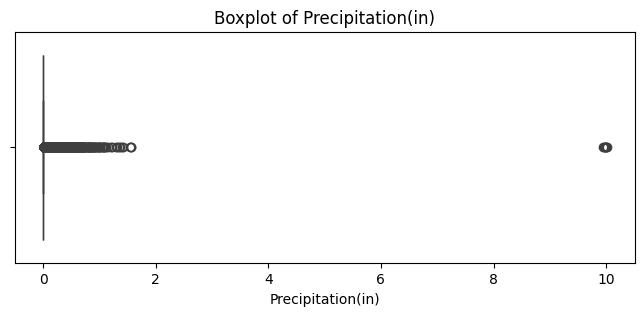

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
features = [
    "Distance(mi)",
    "Temperature(F)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)"
]
for col in features:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df_sample[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

In [ ]:
df_sample.groupby("Severity")[
    ["Temperature(F)",
     "Visibility(mi)",
     "Wind_Speed(mph)",
     "Distance(mi)"]
].median()

In [ ]:
numeric_features = [
    "Severity",
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "Distance(mi)"
]
corr = df_sample[numeric_features].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

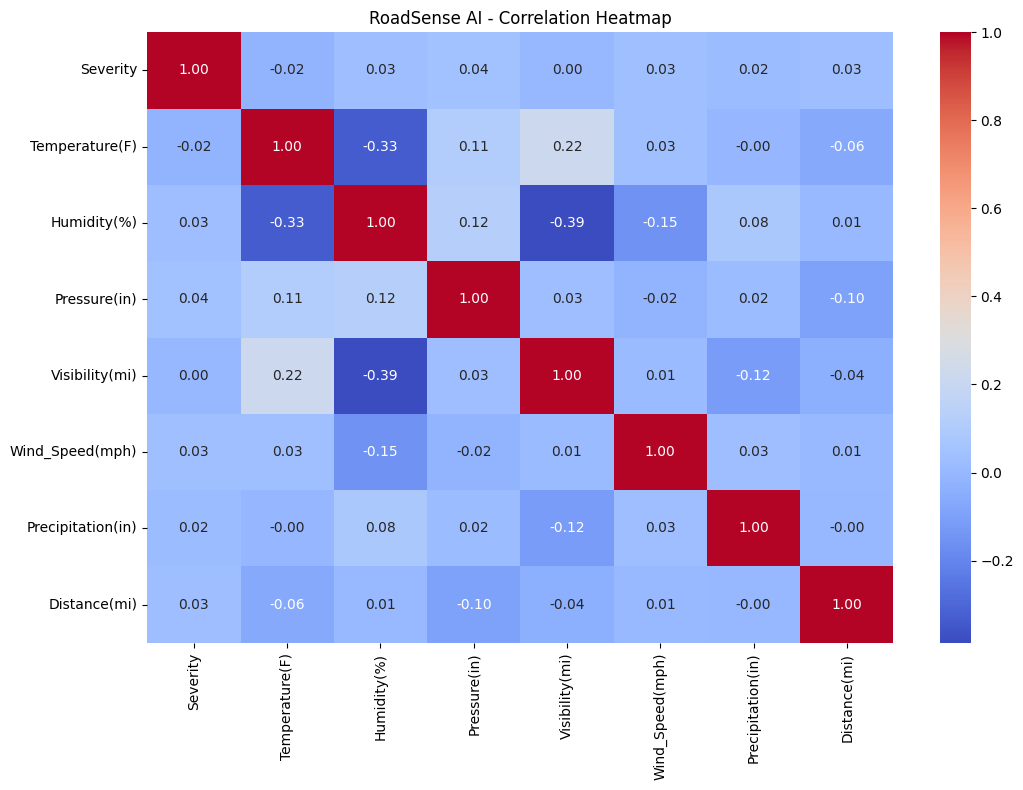

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_features = [
    "Severity",
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "Distance(mi)"
]

corr = df_sample[numeric_features].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("RoadSense AI - Correlation Heatmap")
plt.tight_layout()
plt.show()

In [13]:
# Make a copy of the dataset
work = df_sample.copy()

# Convert Start_Time into datetime
work["Start_Time"] = pd.to_datetime(
    work["Start_Time"],
    errors="coerce"
)

# Extract time-based features
work["start_hour"] = work["Start_Time"].dt.hour
work["start_dayofweek"] = work["Start_Time"].dt.dayofweek
work["start_month"] = work["Start_Time"].dt.month

# Weekend: 1 = Saturday/Sunday, 0 = weekday
work["is_weekend"] = (
    work["start_dayofweek"].isin([5, 6])
).astype(int)

# Check the new features
work[[
    "Start_Time",
    "start_hour",
    "start_dayofweek",
    "start_month",
    "is_weekend"
]].head()

,Start_Time,start_hour,start_dayofweek,start_month,is_weekend
7133276,2020-04-17 09:29:30,9.0,4.0,4.0,0
5363845,NaT,NaN,NaN,NaN,0
155993,2016-08-12 16:45:00,16.0,4.0,8.0,0
1861414,2019-09-20 15:22:16,15.0,4.0,9.0,0
2021359,2019-06-03 16:55:43,16.0,0.0,6.0,0


In [16]:
import numpy as np

work["is_weekend"] = np.where(
    work["start_dayofweek"].isna(),
    np.nan,
    work["start_dayofweek"].isin([5, 6]).astype(float)
)

In [17]:
numeric_features = [
    "Start_Lat",
    "Start_Lng",
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "start_hour",
    "start_dayofweek",
    "start_month",
    "is_weekend"
]

categorical_features = [
    "State",
    "Weather_Condition",
    "Wind_Direction",
    "Sunrise_Sunset"
]

road_features = [
    "Amenity", "Bump", "Crossing", "Give_Way",
    "Junction", "No_Exit", "Railway", "Roundabout",
    "Station", "Stop", "Traffic_Calming",
    "Traffic_Signal", "Turning_Loop"
]

# Combine features
X = work[numeric_features + categorical_features + road_features]

# Target variable
y = work["Severity"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts().sort_index())

Features shape: (100000, 29)
Target shape: (100000,)

Target distribution:
Severity
1      839
2    79595
3    16849
4     2717
Name: count, dtype: int64


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features: (80000, 29)
Testing features: (20000, 29)

Training target distribution:
Severity
1      671
2    63676
3    13479
4     2174
Name: count, dtype: int64

Testing target distribution:
Severity
1      168
2    15919
3     3370
4      543
Name: count, dtype: int64


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine all preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
        ("road", SimpleImputer(strategy="most_frequent"), road_features)
    ]
)

# Complete ML pipeline
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [21]:
# Convert Boolean road features into integers
X_train = X_train.copy()
X_test = X_test.copy()

X_train[road_features] = X_train[road_features].astype("int8")
X_test[road_features] = X_test[road_features].astype("int8")

print(X_train[road_features].dtypes)

Amenity            int8
Bump               int8
Crossing           int8
Give_Way           int8
Junction           int8
No_Exit            int8
Railway            int8
Roundabout         int8
Station            int8
Stop               int8
Traffic_Calming    int8
Traffic_Signal     int8
Turning_Loop       int8
dtype: object


In [22]:
# Train Logistic Regression
lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [23]:
y_pred = lr_model.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, labels=[1, 2, 3, 4]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[1, 2, 3, 4]))

Accuracy: 0.3985
Macro F1: 0.27516382449726995
Balanced Accuracy: 0.5356305688261762

Classification Report:
              precision    recall  f1-score   support

           1       0.03      0.77      0.06       168
           2       0.90      0.37      0.53     15919
           3       0.35      0.49      0.41      3370
           4       0.06      0.51      0.11       543

    accuracy                           0.40     20000
   macro avg       0.33      0.54      0.28     20000
weighted avg       0.78      0.40      0.49     20000


Confusion Matrix:
[[ 129   14    8   17]
 [3422 5906 3031 3560]
 [ 422  552 1657  739]
 [  84   77  104  278]]


In [24]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

# Logistic Regression without class balancing
lr_unbalanced = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train
lr_unbalanced.fit(X_train, y_train)

# Predict
y_pred_unbalanced = lr_unbalanced.predict(X_test)

# Evaluate
print("Accuracy:",
      accuracy_score(y_test, y_pred_unbalanced))

print("Macro F1:",
      f1_score(y_test, y_pred_unbalanced, average="macro"))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_pred_unbalanced))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_unbalanced,
    labels=[1, 2, 3, 4],
    zero_division=0
))

Accuracy: 0.7964
Macro F1: 0.2621182208021314
Balanced Accuracy: 0.2694980458377659

Classification Report:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00       168
           2       0.81      0.98      0.89     15919
           3       0.48      0.10      0.16      3370
           4       0.00      0.00      0.00       543

    accuracy                           0.80     20000
   macro avg       0.32      0.27      0.26     20000
weighted avg       0.72      0.80      0.73     20000



In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

rf_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [26]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred_rf = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("Macro F1:",
      f1_score(y_test, y_pred_rf, average="macro"))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=[1, 2, 3, 4],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_rf,
    labels=[1, 2, 3, 4]
))

Accuracy: 0.7168
Macro F1: 0.3814982408423786
Balanced Accuracy: 0.4234287113765734

Classification Report:
              precision    recall  f1-score   support

           1       0.09      0.24      0.14       168
           2       0.88      0.77      0.82     15919
           3       0.39      0.57      0.46      3370
           4       0.11      0.10      0.11       543

    accuracy                           0.72     20000
   macro avg       0.37      0.42      0.38     20000
weighted avg       0.77      0.72      0.74     20000


Confusion Matrix:
[[   41   112    13     2]
 [  318 12313  2887   401]
 [   68  1316  1925    61]
 [    6   327   153    57]]


In [28]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

gb_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

In [29]:
rf_tuned = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=30,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

rf_tuned.fit(X_train, y_train)

y_pred_tuned = rf_tuned.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Macro F1:", f1_score(y_test, y_pred_tuned, average="macro"))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred_tuned))

print(classification_report(
    y_test, y_pred_tuned,
    labels=[1, 2, 3, 4],
    zero_division=0
))

Accuracy: 0.7758
Macro F1: 0.37170796704167175
Balanced Accuracy: 0.36474839520822405
              precision    recall  f1-score   support

           1       0.21      0.11      0.15       168
           2       0.85      0.88      0.87     15919
           3       0.43      0.45      0.44      3370
           4       0.15      0.02      0.03       543

    accuracy                           0.78     20000
   macro avg       0.41      0.36      0.37     20000
weighted avg       0.76      0.78      0.77     20000



In [30]:
custom_rf = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=2,
        class_weight={
            1: 5,
            2: 1,
            3: 2,
            4: 5
        },
        random_state=42,
        n_jobs=-1
    ))
])

custom_rf.fit(X_train, y_train)

y_pred_custom = custom_rf.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, y_pred_custom))

print("Macro F1:",
      f1_score(y_test, y_pred_custom, average="macro"))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_pred_custom))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_custom,
    labels=[1, 2, 3, 4],
    zero_division=0
))

Accuracy: 0.8016
Macro F1: 0.3232395504299463
Balanced Accuracy: 0.30928829268396507

Classification Report:
              precision    recall  f1-score   support

           1       0.50      0.04      0.07       168
           2       0.83      0.96      0.89     15919
           3       0.51      0.24      0.33      3370
           4       0.80      0.01      0.01       543

    accuracy                           0.80     20000
   macro avg       0.66      0.31      0.32     20000
weighted avg       0.77      0.80      0.76     20000



In [31]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

smote_rf = ImbPipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("smote", SMOTE(
        random_state=42,
        sampling_strategy="not majority",
        k_neighbors=3
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
smote_rf.fit(X_train, y_train)

# Predict
y_pred_smote = smote_rf.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred_smote))
print("Macro F1:", f1_score(y_test, y_pred_smote, average="macro"))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred_smote))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_smote,
    labels=[1, 2, 3, 4],
    zero_division=0
))

Accuracy: 0.73385
Macro F1: 0.3818843341751393
Balanced Accuracy: 0.4146769019154616

Classification Report:
              precision    recall  f1-score   support

           1       0.10      0.24      0.14       168
           2       0.87      0.81      0.84     15919
           3       0.40      0.52      0.45      3370
           4       0.10      0.09      0.10       543

    accuracy                           0.73     20000
   macro avg       0.37      0.41      0.38     20000
weighted avg       0.76      0.73      0.75     20000



In [32]:
import joblib

joblib.dump(rf_model, "roadsense_random_forest.pkl")
joblib.dump(smote_rf, "roadsense_smote_random_forest.pkl")

print("Models saved successfully!")

Models saved successfully!


In [1]:
import sklearn
print(sklearn.__version__)

1.6.1
